# Phase 3 — PyTorch multi-window text classifier

**Medical Document Assistant · Deep Learning**

This notebook reviews the trained TextCNN: tokenizer/vocabulary, Dataset/DataLoader, context coverage, eight hyperparameter trials, early stopping, final refit, frozen-test comparison, source-linked errors, and standalone checkpoint inference.

Run `python -m medical_doc_assistant phase3` first. This notebook reads the completed experiment and demonstrates its components; it does not retrain the candidates. The corpus and record split are the same as Phase 2.

As specified in the plan, this project is informational only and is not medical advice.

In [1]:
import json
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display
from medical_doc_assistant.deep_learning import make_loader
from medical_doc_assistant.neural_model import classify_neural_text, load_checkpoint
from medical_doc_assistant.neural_text import MedicineTextDataset, Vocabulary, encode_document, tokenize

ROOT = Path.cwd()
if not (ROOT / 'configs' / 'phase3.json').exists():
    ROOT = ROOT.parent
REPORTS = ROOT / 'reports' / 'phase3'
assert (REPORTS / 'run_manifest.json').exists(), 'Run python -m medical_doc_assistant phase3 first.'
run = json.loads((REPORTS / 'run_manifest.json').read_text(encoding='utf-8'))
config = run['config']
torch.set_num_threads(config['cpu_threads'])
selection = json.loads((REPORTS / 'model_selection.json').read_text(encoding='utf-8'))
selected = next(result for result in selection['results'] if result['trial_id'] == run['selected_trial'])
pd.set_option('display.max_colwidth', 90)
print('PyTorch:', torch.__version__)
print('Training runtime:', run['environment'])

PyTorch: 2.8.0+cpu
Training runtime: {'python': '3.10.6', 'torch': '2.8.0+cpu', 'device': 'cpu', 'cpu_threads': 4, 'cuda_available': False, 'numpy': '2.2.6', 'pandas': '2.3.3', 'scikit-learn': '1.7.2'}


## 1. Frozen source data and evaluation groups

All 2,471 Phase 1 documents retain their Phase 2 record assignments. Ingredient components remain intact, with 67 training, 18 validation, and 15 test components. The same six source-derived target labels are used for all models.

In [2]:
assignments = pd.read_csv(ROOT / 'data' / 'splits' / 'phase2_split.csv')
df = pd.read_parquet(ROOT / 'data' / 'processed' / 'medicine_labels.parquet').merge(
    assignments[['record_id', 'split', 'benchmark_group_id']], on='record_id', validate='one_to_one')
display(df.groupby('split').agg(documents=('record_id', 'size'), groups=('benchmark_group_id', 'nunique')).reindex(['train', 'validation', 'test']))
assert df.groupby('benchmark_group_id')['split'].nunique().eq(1).all()
print('Dataset SHA-256:', run['dataset_sha256'])
print('Split SHA-256:', run['split_sha256'])

,documents,groups
split,,
train,1762,67
validation,367,18
test,342,15


Dataset SHA-256: 3eadaed552f771aae883df674eed9efc38f0cebf86c355041e3bda350e85f23c
Split SHA-256: 9b41f3cf3e5539efa8905b0db37f45ff0abd03b62bd1adf65d05e54630fb389c


## 2. Tokenizer and training-only vocabulary

The fixed Unicode-aware tokenizer retains decimal values, units, negation, and comparison symbols in a lowercase model-input view. The raw clinical document is retained. PAD=0 and UNK=1 are reserved indices. Frequency ordering is deterministic. Tuning vocabulary fits training text; final refit vocabulary fits train + validation, excluding test.

In [3]:
training_vocab = Vocabulary.from_dict(json.loads((REPORTS / 'tuning_vocabulary.json').read_text(encoding='utf-8')))
refit_vocab = Vocabulary.from_dict(json.loads((REPORTS / 'refit_vocabulary.json').read_text(encoding='utf-8')))
source_example = df.loc[df.split.eq('train')].iloc[0]
print('Real source excerpt:', source_example.document_text[:250])
print('Tokens:', tokenize(source_example.document_text[:250]))
print('Reserved indices:', training_vocab.indices['<pad>'], training_vocab.indices['<unk>'])
print('Tuning/refit vocabulary sizes:', len(training_vocab.tokens), len(refit_vocab.tokens))
display(pd.DataFrame({'token': training_vocab.tokens[:15], 'frequency': training_vocab.frequencies[:15]}))

Real source excerpt: Indications And Usage
1 INDICATIONS AND USAGE Omeprazole is a proton pump inhibitor (PPI) indicated for the: Treatment of active duodenal ulcer in adults ( 1.1 ) Eradication of Helicobacter pylori to reduce the risk of duodenal ulcer recurrence in ad
Tokens: ['indications', 'and', 'usage', '1', 'indications', 'and', 'usage', 'omeprazole', 'is', 'a', 'proton', 'pump', 'inhibitor', 'ppi', 'indicated', 'for', 'the', 'treatment', 'of', 'active', 'duodenal', 'ulcer', 'in', 'adults', '1.1', 'eradication', 'of', 'helicobacter', 'pylori', 'to', 'reduce', 'the', 'risk', 'of', 'duodenal', 'ulcer', 'recurrence', 'in', 'ad']
Reserved indices: 0 1
Tuning/refit vocabulary sizes: 17745 20000


,token,frequency
0,<pad>,0
1,<unk>,0
2,of,290494
3,the,239204
4,and,236592
5,in,195587
6,to,155681
7,with,108519
8,or,97868
9,patients,91579


## 3. PyTorch Dataset and DataLoader

A sample is one source document represented as up to eight contiguous 256-token windows. Long labels include the first/last passages and evenly spaced middle passages. Short labels are fully retained and right-padded. Only encoded text enters the model; class IDs are loss targets and record indices preserve output order.

In [4]:
small = df.loc[df.split.eq('train')].head(3).reset_index(drop=True)
dataset = MedicineTextDataset.from_frame(small, training_vocab, config['encoding'], run['class_labels'])
loader = make_loader(dataset, 3, False, config)
batch = next(iter(loader))
print('Input tensor [batch, chunks, length]:', tuple(batch['input_ids'].shape))
print('Target class IDs:', batch['target'].tolist())
print('Source record indices:', batch['index'].tolist())
display(dataset.coverage_table(small))

Input tensor [batch, chunks, length]: (3, 8, 256)
Target class IDs: [4, 4, 4]
Source record indices: [0, 1, 2]


,record_id,class_label,split,benchmark_group_id,token_count,encoded_tokens,chunks,retention_ratio,unknown_tokens,unknown_ratio
0,014f4683-5caa-4eac-95ca-54ac52ac7423,acid_reducer,train,benchmark_8e4e3c26861a2274,15785,2048,8,0.129743,0,0.0
1,01e166d4-7ac5-421f-87d2-7b647631bf8d,acid_reducer,train,benchmark_8e4e3c26861a2274,640,640,3,1.000000,0,0.0
2,02d57009-ba37-4b5d-af59-7a62f1d9e29c,acid_reducer,train,benchmark_e73737fb27f505ee,6141,2048,8,0.333496,0,0.0


## 4. Padding-aware multi-window TextCNN

A learned 64-dimensional embedding feeds Conv1D banks with kernel widths 3/4/5 and 32 filters each. Padding-touching convolution windows are excluded. Max/mean window features and an embedding mean are pooled at document level, followed by dropout and a six-class linear head. Convolutions do not cross the gaps between sampled passages.

In [5]:
checkpoint_path = ROOT / 'models' / 'phase3' / 'text_cnn.pt'
bundle = load_checkpoint(checkpoint_path)
model = bundle['model']
print(model)
print('Learnable parameters:', sum(parameter.numel() for parameter in model.parameters()))
print('Final fit provenance:', bundle['provenance'])

TextCNN(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (embedding_dropout): Dropout(p=0.5, inplace=False)
  (convolutions): ModuleList(
    (0): Conv1d(64, 32, kernel_size=(3,), stride=(1,))
    (1): Conv1d(64, 32, kernel_size=(4,), stride=(1,))
    (2): Conv1d(64, 32, kernel_size=(5,), stride=(1,))
  )
  (output_dropout): Dropout(p=0.5, inplace=False)
  (classifier): Linear(in_features=256, out_features=6, bias=True)
)
Learnable parameters: 1306214
Final fit provenance: {'dataset_sha256': '3eadaed552f771aae883df674eed9efc38f0cebf86c355041e3bda350e85f23c', 'split_sha256': '9b41f3cf3e5539efa8905b0db37f45ff0abd03b62bd1adf65d05e54630fb389c', 'config_sha256': '43d5606c80a45f9faf1f35baba04d827df005f1c80ea0aa72066242a74dee8ba', 'tuning_vocabulary_sha256': '262995de6a29fecd38f35decb6e4ec3de13cb6cb9ea031b15defbac6abf6749f', 'fitted_partitions': ['train', 'validation'], 'vocabulary_fitted_partitions': ['train', 'validation'], 'fitted_documents': 2129, 'epoch': 23, 'selected_trial': 'tria

## 5. Context coverage and unknown tokens

The CNN uses at most 2,048 regex tokens per document. TF-IDF uses full source text. This is an explicit input-budget difference in the comparison. Coverage diagnostics distinguish full token counts, sampled token counts, and unknown tokens relative to the fitted vocabulary.

,token_count,encoded_tokens,retention_ratio,unknown_ratio
split,,,,
train,4372.175936,1419.701476,0.657367,0.001353
validation,7995.168937,1924.534060,0.414662,0.000298
test,9564.421053,1978.119883,0.341671,0.014334


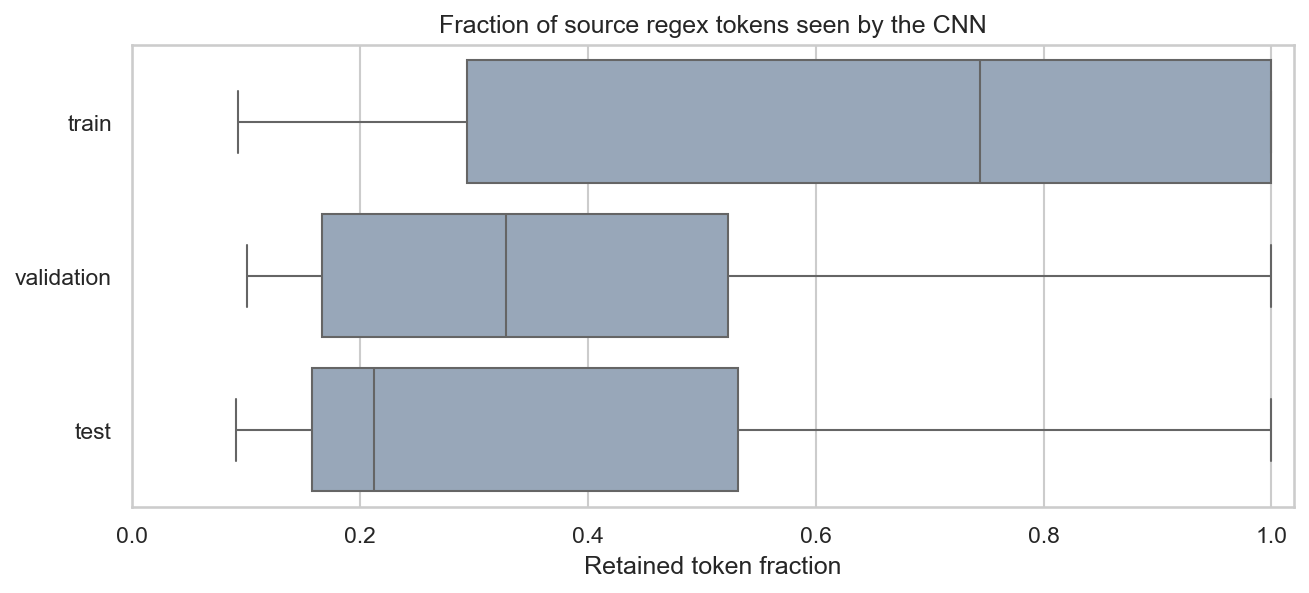

In [6]:
coverage = pd.read_csv(REPORTS / 'token_coverage.csv')
display(coverage.groupby('split')[['token_count', 'encoded_tokens', 'retention_ratio', 'unknown_ratio']].mean().reindex(['train', 'validation', 'test']))
display(Image(filename=str(REPORTS / 'figures' / 'token_coverage.png')))

## 6. Hyperparameter trials

Eight learning-rate/batch-size/dropout combinations were fixed before training. AdamW uses class-weighted cross-entropy, weight decay, and gradient clipping. Seeds are reset for each trial. Selection uses validation macro F1, then lower validation loss and fixed trial order.

,learning_rate,batch_size,dropout,trial_id,best_epoch,epochs_run,stopped_early,validation_macro_f1,validation_accuracy,validation_loss,training_seconds
0,0.001,16,0.2,trial_01,19,24,False,0.976047,0.975477,0.090938,170.684298
1,0.001,16,0.5,trial_02,24,24,False,0.974082,0.972752,0.090936,167.339049
2,0.001,32,0.2,trial_03,7,12,True,0.974103,0.972752,0.301694,79.834738
3,0.001,32,0.5,trial_04,13,18,True,0.919648,0.915531,0.379491,121.299580
4,0.003,16,0.2,trial_05,3,8,True,0.940561,0.940054,0.199044,55.195357
5,0.003,16,0.5,trial_06,13,18,True,0.987014,0.986376,0.038554,123.956180
6,0.003,32,0.2,trial_07,13,18,True,0.986536,0.986376,0.050568,119.977043
7,0.003,32,0.5,trial_08,23,23,True,0.997238,0.997275,0.026204,165.537153


Selected trial: trial_08
Selected parameters: {'learning_rate': 0.003, 'batch_size': 32, 'dropout': 0.5}


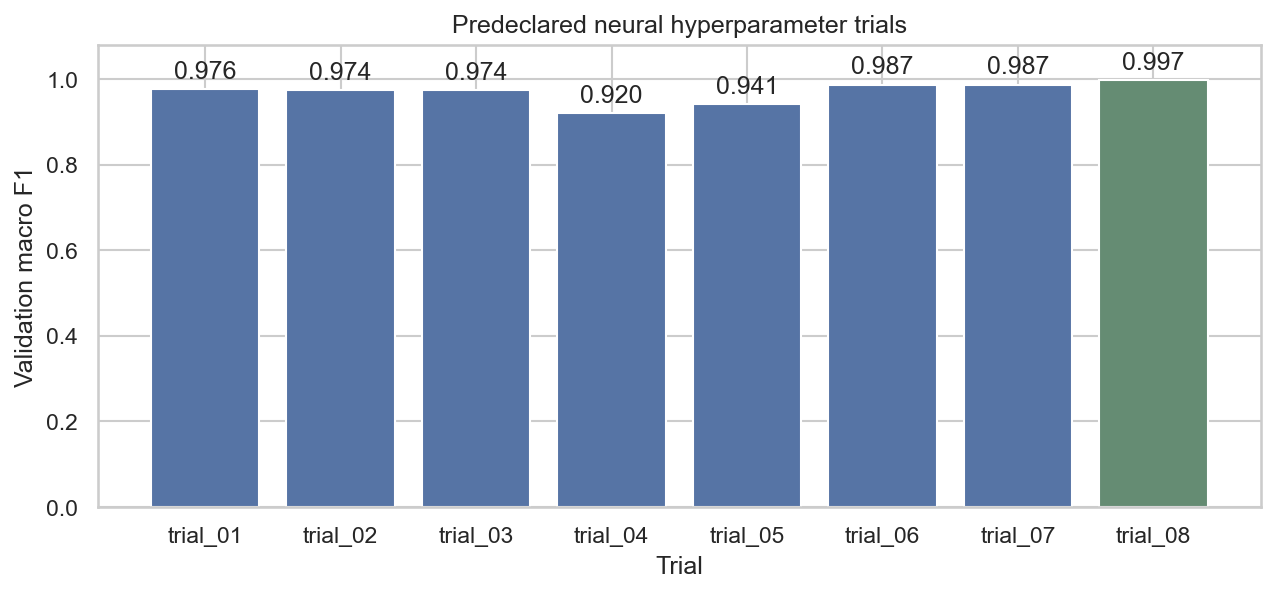

In [7]:
trials = pd.read_csv(REPORTS / 'trial_comparison.csv')
display(trials)
print('Selected trial:', run['selected_trial'])
print('Selected parameters:', selected['parameters'])
display(Image(filename=str(REPORTS / 'figures' / 'trial_comparison.png')))

## 7. Early stopping and learning curves

The epoch limit is 24 with patience 5 and meaningful macro-F1 improvement 0.0001. Checkpoints retain the highest validation score and lowest loss on ties. Tied checkpoint updates do not reset patience. Training accuracy/loss are online training-mode diagnostics; validation uses evaluation mode.

,trial_id,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,validation_group_balanced_macro_f1,epoch_seconds
15,trial_08,16,0.063767,0.981271,0.052000,0.986376,0.987014,0.950235,6.713350
16,trial_08,17,0.061814,0.979001,0.073220,0.967302,0.968512,0.941764,6.731638
17,trial_08,18,0.052549,0.984109,0.029304,0.997275,0.997238,0.998952,6.637406
18,trial_08,19,0.044287,0.988082,0.024747,0.994550,0.994340,0.996643,6.781113
19,trial_08,20,0.042377,0.990919,0.040641,0.978202,0.978715,0.990447,8.521682
20,trial_08,21,0.028075,0.989784,0.063829,0.972752,0.974082,0.945071,10.120688
21,trial_08,22,0.035636,0.988082,0.043553,0.989101,0.989577,0.963353,9.994137
22,trial_08,23,0.028755,0.989217,0.026204,0.997275,0.997238,0.998952,9.873251


Best checkpoint epoch / epochs run: 23 23


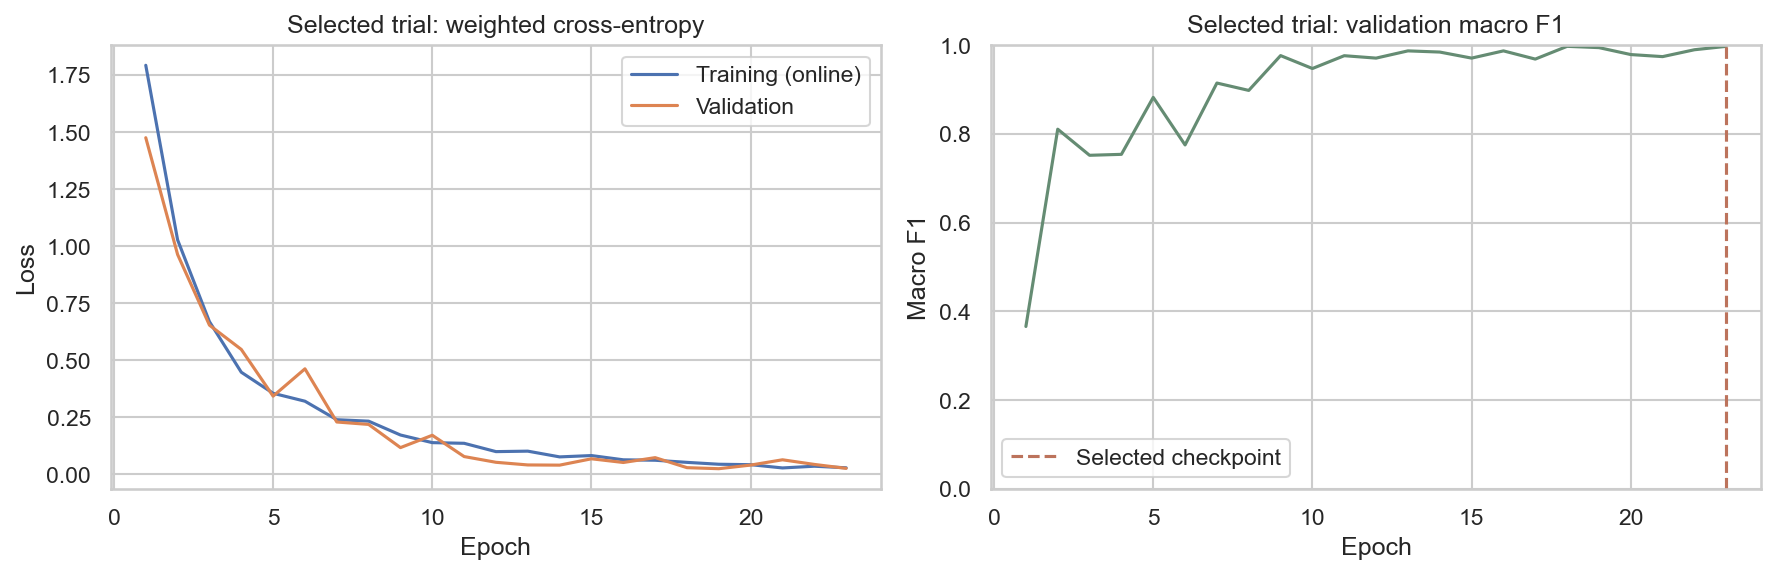

In [8]:
history = pd.read_csv(ROOT / selected['history_path'])
display(history.tail(8))
print('Best checkpoint epoch / epochs run:', selected['best_epoch'], selected['epochs_run'])
display(Image(filename=str(REPORTS / 'figures' / 'learning_curves.png')))

## 8. Pre-test selection and fixed final refit

The selected epoch count is fixed before the final model is trained fresh on train + validation. The final vocabulary is also relearned from those partitions. The refit has no holdout monitoring. Test encoding/inference follows selection and refit.

In [9]:
print('Selection timestamp:', selection['selected_at_utc'])
print('Test evaluation timestamp:', run['test_evaluation_started_at_utc'])
print('Fixed refit epochs:', run['refit_epochs'])
display(pd.read_csv(REPORTS / 'refit_history.csv').tail())
assert selection['test_used_for_selection'] is False
assert len(pd.read_csv(REPORTS / 'refit_history.csv')) == selected['best_epoch']

Selection timestamp: 2026-10-28T14:45:52+00:00
Test evaluation timestamp: 2026-10-28T14:50:29+00:00
Fixed refit epochs: 23


,epoch,train_loss,train_accuracy
18,19,0.024809,0.990606
19,20,0.035481,0.988257
20,21,0.022443,0.992954
21,22,0.021360,0.993894
22,23,0.013172,0.995773


## 9. Frozen-test comparison with the classical baselines

All models use the same source corpus and record split. The reported validation score belongs to the selected tuning checkpoint; test metrics belong to the final train/validation refit. Classical scores are copied from the recorded Phase 2 experiment.

,model,display_name,phase,validation_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_group_balanced_macro_f1,classical_benchmark
0,logistic_regression,Logistic Regression,2,0.835485,0.976608,0.981481,0.980676,0.979940,0.932692,False
1,linear_svm,Linear SVM,2,0.856522,0.956140,0.968354,0.963768,0.962192,0.964286,False
2,random_forest,Random Forest,2,0.867136,0.970760,0.977186,0.975845,0.975116,0.968761,True
3,text_cnn,PyTorch TextCNN,3,0.997238,0.985380,0.987597,0.987923,0.987595,0.985869,False


Macro-F1 difference from Random Forest: 0.012478511901456657


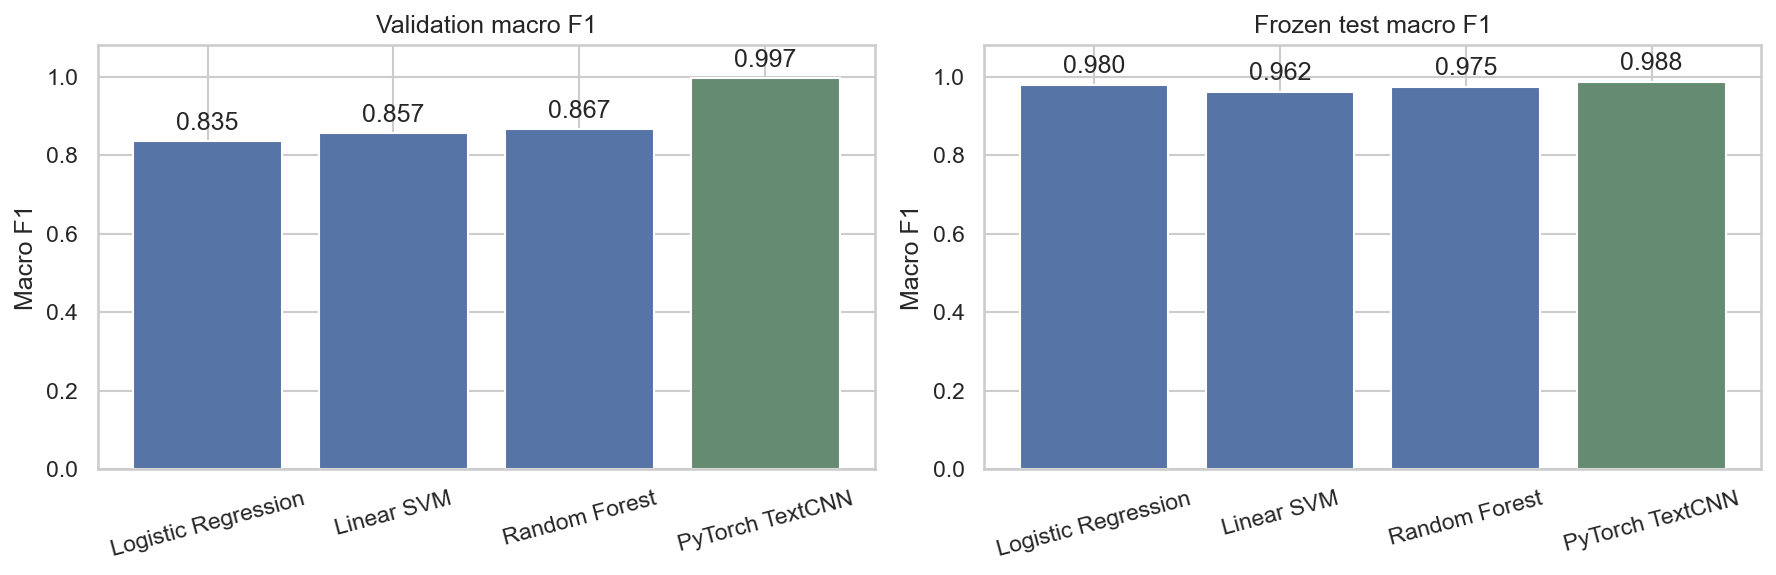

In [10]:
comparison = pd.read_csv(REPORTS / 'model_comparison.csv')
display(comparison)
print('Macro-F1 difference from Random Forest:', run['test_macro_f1_difference_from_benchmark'])
display(Image(filename=str(REPORTS / 'figures' / 'baseline_comparison.png')))

## 10. Class results and errors

The confusion matrix uses source target classes as rows and predictions as columns. Macro precision/recall/F1 average over all six fixed labels. Group-balanced metrics supplement document-level results. The test has only 15 independent components; the labels are automatic metadata targets rather than expert-confirmed medical indications.

,model,class_label,precision,recall,f1,support,groups
0,text_cnn,antibacterial,0.984848,0.942029,0.962963,69,5
1,text_cnn,anti_inflammatory_nsaid,1.000000,1.000000,1.000000,64,2
2,text_cnn,corticosteroid,0.955224,1.000000,0.977099,64,2
3,text_cnn,antifungal,0.985507,0.985507,0.985507,69,2
4,text_cnn,acid_reducer,1.000000,1.000000,1.000000,19,2
5,text_cnn,antihypertensive,1.000000,1.000000,1.000000,57,3


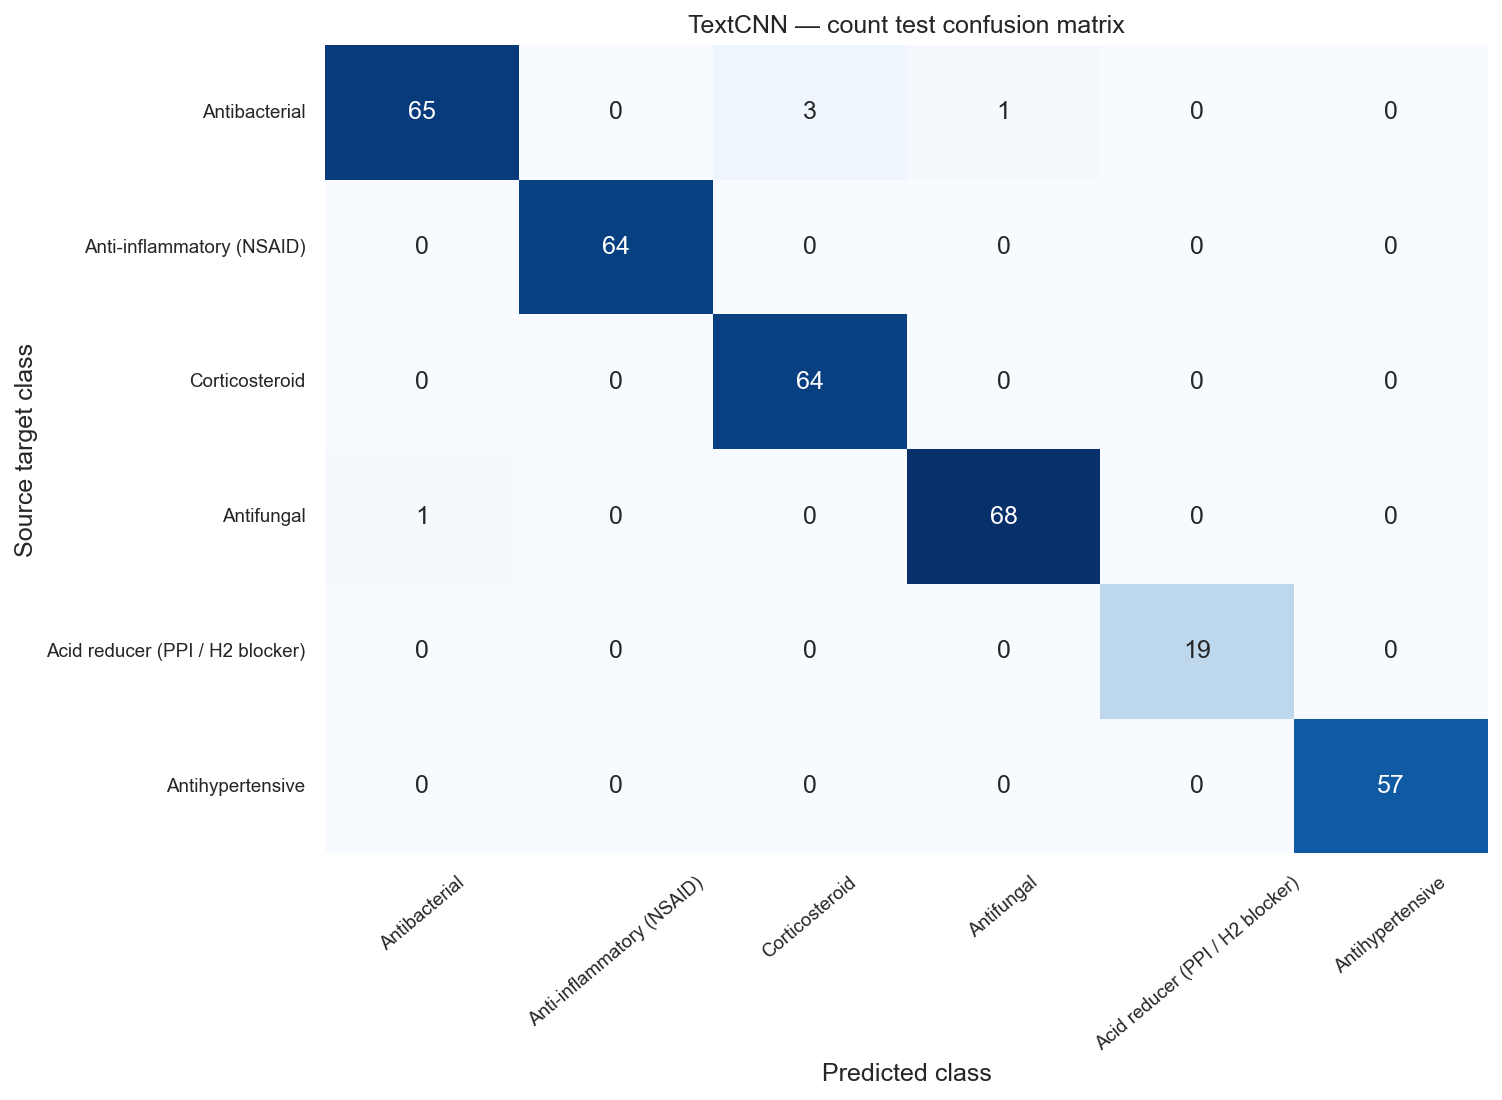

In [11]:
display(pd.read_csv(REPORTS / 'per_class_test_metrics.csv'))
display(Image(filename=str(REPORTS / 'figures' / 'confusion_matrix.png')))

In [12]:
errors = pd.read_csv(REPORTS / 'test_errors.csv')
print('Test document errors:', len(errors))
display(errors[['record_id', 'generic_names', 'true_class', 'predicted_class', 'source_url']])

Test document errors: 5


,record_id,generic_names,true_class,predicted_class,source_url
0,20d6d1c8-8974-4166-b224-d3b7e0c202d6,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=c4b5bb1f-e158-4ac1-9c35-e98a4...
1,48d4400d-e246-f109-e063-6394a90a8103,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=75df79e9-f064-4f46-9837-8d4d5...
2,a6d68829-f7b6-4b9b-ad44-110c47609918,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=a6d68829-f7b6-4b9b-ad44-110c4...
3,d34d6f39-c5c7-40ea-89da-977c6e1eaa05,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=7c752fac-8ec8-49ab-8570-09d2a...
4,2de57c37-2e52-4d57-89e9-33a922f9f101,"[""VORICONAZOLE""]",antifungal,antibacterial,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=16a80777-f1f3-45bb-a312-998b0...


## 11. Optional representation visualization

PCA shows the final CNN's pooled representations for training documents only. This is exploratory feature visualization, not independent evaluation or medical clustering evidence.

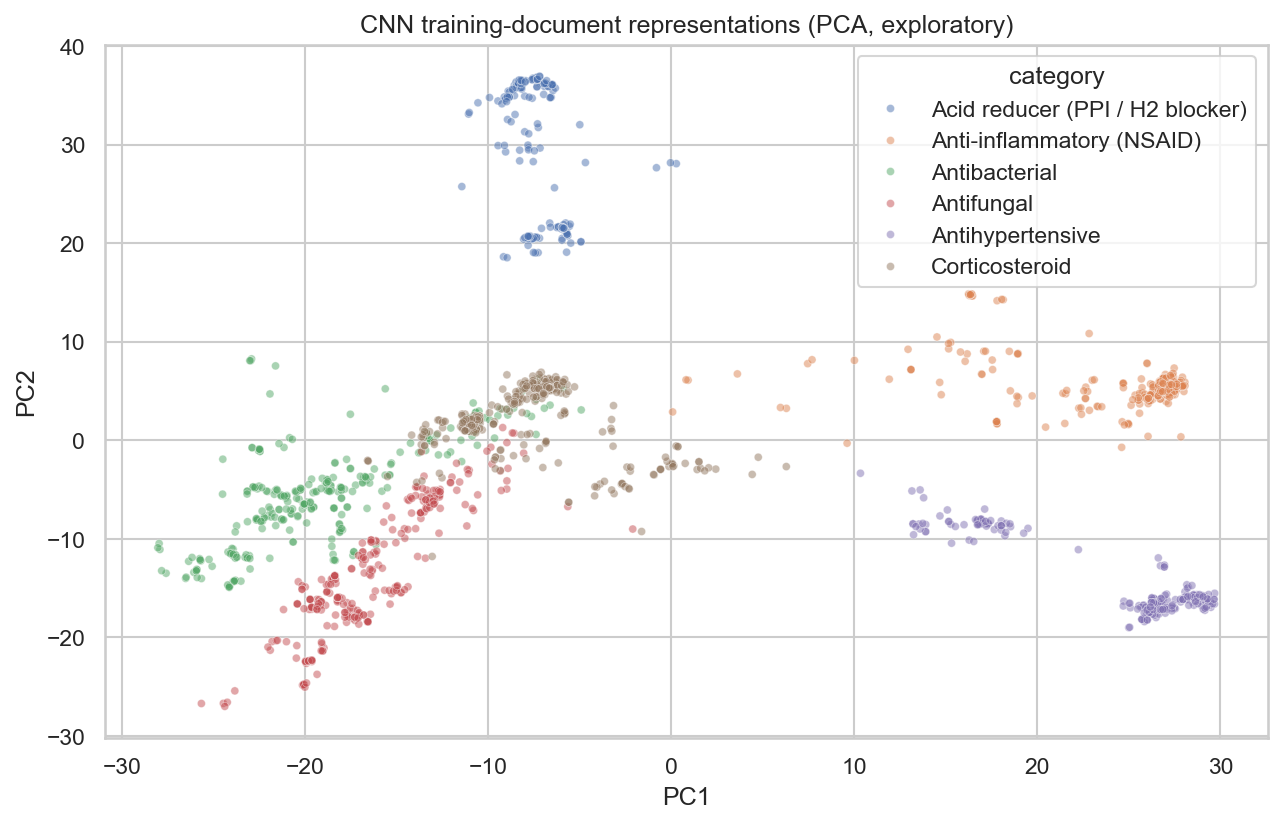

In [13]:
display(Image(filename=str(REPORTS / 'figures' / 'training_embedding_projection.png')))

## 12. Standalone checkpoint inference

The checkpoint stores model state, vocabulary, label order, encoding settings, and provenance. This example is the same real source-backed leaflet used by the Phase 2 demonstration. Only its text is passed to inference.

In [14]:
text = (ROOT / 'data' / 'examples' / 'phase2_demo_leaflet.txt').read_text(encoding='utf-8')
provenance = json.loads((ROOT / 'data' / 'examples' / 'phase2_demo_leaflet.json').read_text(encoding='utf-8'))
result = classify_neural_text(checkpoint_path, text)
display(pd.Series({'source_target': provenance['class_label'], 'prediction': result['predicted_class'], 'source_url': provenance['source_url'], 'tokens': result['token_count'], 'tokens_seen': result['encoded_tokens']}))

source_target                                                                                 acid_reducer
prediction                                                                                    acid_reducer
source_url       https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=29eb7b87-59a4-4d27-ad53-789da...
tokens                                                                                                 598
tokens_seen                                                                                            598
dtype: object

## 13. Padding-invariance demonstration

An empty chunk must not change the model's representation. Padding-touching windows are masked, and embedding means use only real tokens.

In [15]:
encoded, _ = encode_document(text, bundle['vocabulary_object'], bundle['encoding_settings'])
inputs = torch.from_numpy(encoded).unsqueeze(0)
padded = torch.cat([inputs, torch.zeros_like(inputs[:, :2])], dim=1)
with torch.inference_mode():
    original_logits, padded_logits = model(inputs), model(padded)
torch.testing.assert_close(original_logits, padded_logits, atol=1e-5, rtol=1e-5)
print('Adding all-padding chunks preserves logits.')

Adding all-padding chunks preserves logits.


## 14. Verification and review checkpoint

Checks cover source/group isolation, vocabulary fitting, the trial plan, validation checkpoint selection, fixed refit epochs, tensor state/dimensions, padding invariance, prediction/logit/loss consistency, and baseline comparison provenance. Software regression tests also verify actual learning on isolated non-medical fixtures.

In [16]:
verification = json.loads((REPORTS / 'validation.json').read_text(encoding='utf-8'))
assert verification['all_passed']
assert verification['selected_trial'] == run['selected_trial']
print('Passed experiment checks:', len(verification['checks']))
display(pd.DataFrame(verification['checks'])[['name', 'passed']])
print('Phase 3 is ready for review.')

Passed experiment checks:

 95


,name,passed
0,all_documents_accounted_for,True
1,three_partitions,True
2,benchmark_groups_disjoint,True
3,phase1_groups_preserved,True
4,all_classes_in_each_partition,True
...,...,...
90,output_checksum_trial_06_history.csv,True
91,output_checksum_trial_07_history.csv,True
92,output_checksum_trial_08_history.csv,True
93,output_checksum_trial_comparison.csv,True


Phase 3 is ready for review.


## Stop for Phase 3 review

Review `reports/phase_3_review.md`, the learning curves, context coverage, full model comparison, source-linked errors, and `docs/neural_model_card.md`.

After review, Phase 4 will address BERT fine-tuning and the document-grounded RAG chatbot.

Data provided by the U.S. Food and Drug Administration (https://open.fda.gov). This product uses publicly available data from the U.S. National Library of Medicine (NLM), National Institutes of Health, Department of Health and Human Services; NLM is not responsible for the product and does not endorse or recommend this or any other product.